In [1]:
FILE = "yellow_tripdata_2025-01.parquet"


In [1]:
%pip install pandas numpy scikit-learn matplotlib seaborn pyarrow

  Using cached pandas-3.1.0-cp311-cp311-win_amd64.whl.metadata (18 kB)
  Using cached numpy-2.4.6-cp311-cp311-win_amd64.whl.metadata (6.6 kB)
  Using cached scikit_learn-1.9.1-cp311-cp311-win_amd64.whl.metadata (9.3 kB)
  Using cached matplotlib-3.11.2-cp311-cp311-win_amd64.whl.metadata (80 kB)
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached pyarrow-26.0.0-cp311-cp311-win_amd64.whl.metadata (3.0 kB)
  Using cached tzdata-2026.5-py2.py3-none-any.whl.metadata (1.4 kB)
  Using cached scipy-1.17.1-cp311-cp311-win_amd64.whl.metadata (60 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached narwhals-2.27.1-py3-none-any.whl.metadata (15 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached contourpy-1.3.3-cp311-cp311-win_amd64.whl.metadata (5.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.67.0-cp311-cp311-win_amd64.whl.metadata (139 kB)
  Using cached


[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report
)


FILE = "yellow_tripdata_2025-01.parquet"
print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
df = pd.read_parquet(
    FILE,
    columns=["tpep_pickup_datetime", "PULocationID"]
)

print("Dataset shape:", df.shape)
display(df.head())
print("\nColumn names:", df.columns.tolist())
print("\nMissing values:\n", df.isnull().sum())

Dataset shape: (3475226, 2)


,tpep_pickup_datetime,PULocationID
0,2025-01-01 00:18:38,229
1,2025-01-01 00:32:40,236
2,2025-01-01 00:44:04,141
3,2025-01-01 00:14:27,244
4,2025-01-01 00:21:34,244



Column names: ['tpep_pickup_datetime', 'PULocationID']

Missing values:
 tpep_pickup_datetime    0
PULocationID            0
dtype: int64


In [ ]:
df = df.dropna(
    subset=["tpep_pickup_datetime", "PULocationID"]
).copy()

df["tpep_pickup_datetime"] = pd.to_datetime(
    df["tpep_pickup_datetime"],
    errors="coerce"
)

df = df.dropna(
    subset=["tpep_pickup_datetime"]
)

# Keep January 2025 records only
df = df[
    (df["tpep_pickup_datetime"] >= "2025-01-01") &
    (df["tpep_pickup_datetime"] < "2025-02-01")
].copy()

print("Cleaned dataset shape:", df.shape)
print("Missing values:\n", df.isnull().sum())
print("Date range:")
print(df["tpep_pickup_datetime"].min())
print(df["tpep_pickup_datetime"].max())

Cleaned dataset shape: (3475204, 2)
Missing values:
 tpep_pickup_datetime    0
PULocationID            0
dtype: int64
Date range:
2025-01-01 00:00:00
2025-01-31 23:59:59


In [7]:
df["hour"] = df["tpep_pickup_datetime"].dt.floor("h")

demand = (
    df.groupby(["PULocationID", "hour"])
      .size()
      .rename("demand")
      .reset_index()
)

display(demand.head())
print("Zone-hour records with at least one pickup:", len(demand))

,PULocationID,hour,demand
0,1,2025-01-01 06:00:00,1
1,1,2025-01-01 09:00:00,4
2,1,2025-01-01 12:00:00,2
3,1,2025-01-01 13:00:00,4
4,1,2025-01-01 14:00:00,2


Zone-hour records with at least one pickup: 97014


In [8]:
zones = sorted(demand["PULocationID"].unique())
start = demand["hour"].min().floor("h")
end = demand["hour"].max().floor("h")
hours = pd.date_range(start, end, freq="h")

grid = pd.MultiIndex.from_product(
    [zones, hours], names=["PULocationID", "hour"]
).to_frame(index=False)

data = grid.merge(demand, on=["PULocationID", "hour"], how="left")
data["demand"] = data["demand"].fillna(0)
data = data.sort_values(["PULocationID", "hour"]).reset_index(drop=True)

grouped = data.groupby("PULocationID")["demand"]
data["lag_1"] = grouped.shift(1)
data["lag_24"] = grouped.shift(24)
data["lag_168"] = grouped.shift(168)
data["hour_of_day"] = data["hour"].dt.hour
data["day_of_week"] = data["hour"].dt.dayofweek
data["next_demand"] = grouped.shift(-1)

print("Hourly zone rows:", len(data))
display(data.head())

Hourly zone rows: 194184


C:\Users\User\AppData\Local\Temp\ipykernel_13440\3096976050.py:19: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  data["day_of_week"] = data["hour"].dt.dayofweek


,PULocationID,hour,demand,lag_1,lag_24,lag_168,hour_of_day,day_of_week,next_demand
0,1,2025-01-01 00:00:00,0.0,NaN,NaN,NaN,0,2,0.0
1,1,2025-01-01 01:00:00,0.0,0.0,NaN,NaN,1,2,0.0
2,1,2025-01-01 02:00:00,0.0,0.0,NaN,NaN,2,2,0.0
3,1,2025-01-01 03:00:00,0.0,0.0,NaN,NaN,3,2,0.0
4,1,2025-01-01 04:00:00,0.0,0.0,NaN,NaN,4,2,0.0


In [9]:
unique_hours = np.sort(data["hour"].unique())
split_index = int(len(unique_hours) * 0.80)
cutoff = pd.Timestamp(unique_hours[split_index])

# Learn each zone's 80th percentile from the training period only.
training_demand = data.loc[data["hour"] < cutoff]
thresholds = training_demand.groupby("PULocationID")["demand"].quantile(0.80)
data["high_threshold"] = data["PULocationID"].map(thresholds)

data = data.dropna(subset=["lag_1", "lag_24", "lag_168", "next_demand", "high_threshold"]).copy()
data["high_demand"] = (data["next_demand"] > data["high_threshold"]).astype(int)

train = data[data["hour"] < cutoff].copy()
test = data[data["hour"] >= cutoff].copy()

features = [
    "PULocationID", "hour_of_day", "day_of_week",
    "lag_1", "lag_24", "lag_168"
]
X_train, y_train = train[features], train["high_demand"]
X_test, y_test = test[features], test["high_demand"]

print("Training rows:", len(train))
print("Testing rows:", len(test))
print("Test period starts:", cutoff)
print("\nTraining target distribution:\n", y_train.value_counts(normalize=True).rename("proportion"))
print("\nTesting target distribution:\n", y_test.value_counts(normalize=True).rename("proportion"))

Training rows: 111447
Testing rows: 38628
Test period starts: 2025-01-25 19:00:00

Training target distribution:
 high_demand
0    0.846968
1    0.153032
Name: proportion, dtype: float64

Testing target distribution:
 high_demand
0    0.84884
1    0.15116
Name: proportion, dtype: float64


In [10]:
categorical_features = ["PULocationID"]
numeric_features = ["hour_of_day", "day_of_week", "lag_1", "lag_24", "lag_168"]

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("numeric", StandardScaler(), numeric_features),
    ]
)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(max_depth=10, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, max_depth=15, class_weight="balanced",
        random_state=42, n_jobs=-1
    ),
}

trained_models = {}
for name, estimator in models.items():
    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", estimator),
    ])
    pipeline.fit(X_train, y_train)
    trained_models[name] = pipeline
    print(f"{name}: trained successfully")

Logistic Regression: trained successfully
Decision Tree: trained successfully
Random Forest: trained successfully



Logistic Regression
               precision    recall  f1-score   support

Normal demand       0.93      0.62      0.75     32789
  High demand       0.26      0.74      0.38      5839

     accuracy                           0.64     38628
    macro avg       0.60      0.68      0.56     38628
 weighted avg       0.83      0.64      0.69     38628



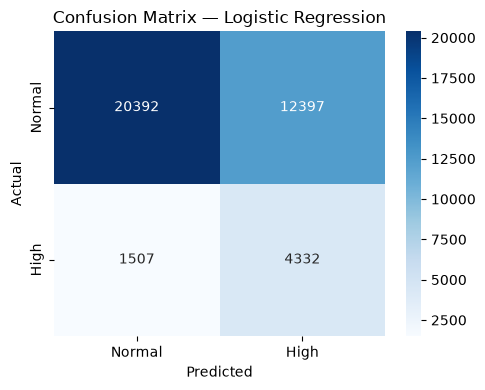


Decision Tree
               precision    recall  f1-score   support

Normal demand       0.93      0.75      0.83     32789
  High demand       0.33      0.69      0.44      5839

     accuracy                           0.74     38628
    macro avg       0.63      0.72      0.64     38628
 weighted avg       0.84      0.74      0.77     38628



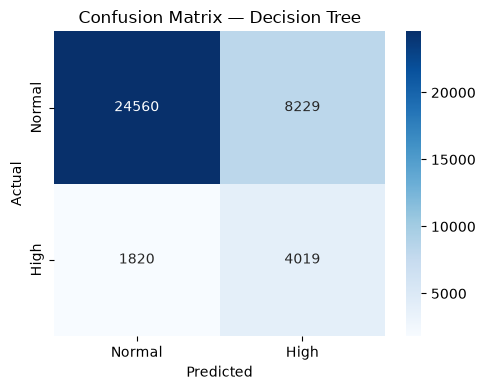


Random Forest
               precision    recall  f1-score   support

Normal demand       0.93      0.68      0.79     32789
  High demand       0.29      0.72      0.41      5839

     accuracy                           0.69     38628
    macro avg       0.61      0.70      0.60     38628
 weighted avg       0.83      0.69      0.73     38628



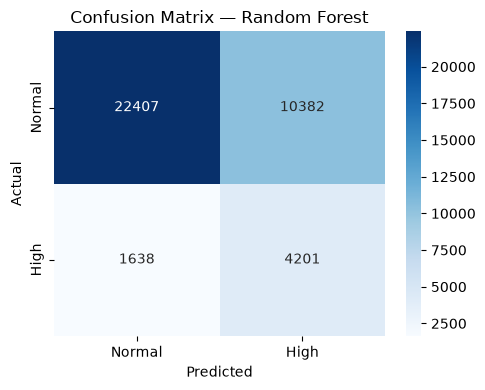

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
1,Decision Tree,0.740,0.328,0.688,0.444,0.789
2,Random Forest,0.689,0.288,0.719,0.411,0.781
0,Logistic Regression,0.640,0.259,0.742,0.384,0.766


In [11]:
results = []

for name, model in trained_models.items():
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    auc = roc_auc_score(y_test, probabilities) if y_test.nunique() == 2 else np.nan
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-score": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": auc,
    })

    print("\n" + "=" * 55)
    print(name)
    print(classification_report(
        y_test, predictions,
        labels=[0, 1], target_names=["Normal demand", "High demand"],
        zero_division=0
    ))

    cm = confusion_matrix(y_test, predictions, labels=[0, 1])
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["Normal", "High"],
                yticklabels=["Normal", "High"])
    plt.title(f"Confusion Matrix — {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()

results_df = pd.DataFrame(results).sort_values("F1-score", ascending=False)
display(results_df.round(3))

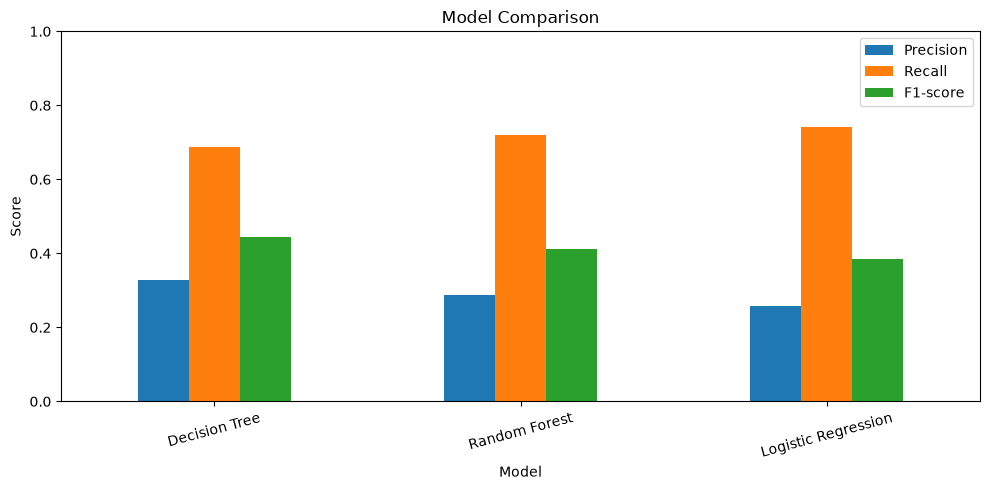

Best model by test F1-score: Decision Tree
Review recall and precision as well before choosing a model for vehicle repositioning.


In [13]:
# Compare precision, recall, and F1-score across models.
results_df.set_index("Model")[["Precision", "Recall", "F1-score"]].plot(
    kind="bar", ylim=(0, 1), figsize=(10, 5)
)
plt.title("Model Comparison")
plt.ylabel("Score")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

best_model_name = results_df.iloc[0]["Model"]
print("Best model by test F1-score:", best_model_name)
print("Review recall and precision as well before choosing a model for vehicle repositioning.")

In [14]:
latest = (
    data.sort_values("hour")
        .groupby("PULocationID")
        .tail(1)
        .copy()
)

X_latest = latest[features]
chosen_model = trained_models[best_model_name]
latest["high_demand_probability"] = chosen_model.predict_proba(X_latest)[:, 1]
latest["predicted_high_demand"] = chosen_model.predict(X_latest)

forecast = latest[[
    "PULocationID", "hour", "high_demand_probability", "predicted_high_demand"
]].sort_values("high_demand_probability", ascending=False)

display(forecast.head(10))
forecast.to_csv("taxi_demand_predictions.csv", index=False)
print("Saved predictions to taxi_demand_predictions.csv")

,PULocationID,hour,high_demand_probability,predicted_high_demand
58774,79,2025-01-31 22:00:00,0.8962,1
135406,186,2025-01-31 22:00:00,0.8962,1
119038,164,2025-01-31 22:00:00,0.8962,1
171118,234,2025-01-31 22:00:00,0.8962,1
50590,68,2025-01-31 22:00:00,0.8962,1
99694,138,2025-01-31 22:00:00,0.8962,1
104158,144,2025-01-31 22:00:00,0.8962,1
114574,158,2025-01-31 22:00:00,0.8962,1
118294,163,2025-01-31 22:00:00,0.8962,1
35710,48,2025-01-31 22:00:00,0.8962,1


Saved predictions to taxi_demand_predictions.csv


## Conclusion

In this project, Logistic Regression, Decision Tree, and Random Forest were implemented to predict pickup zones with unusually high taxi demand in the next hour. Among the three models, Decision Tree performed best, achieving approximately 74% accuracy and an F1-score of 0.44 for high-demand prediction. Logistic Regression achieved 64% accuracy, while Random Forest achieved 69%. Therefore, the Decision Tree model is the most suitable choice among the tested models for identifying potential high-demand zones and helping taxi operators reposition vehicles efficiently. However, its precision for high-demand predictions is only 33%, so further improvements are needed to reduce false alarms and improve prediction reliability.
